# Exam 3 Practice: Non-Linear Modeling and Optimization for Architectural Engineering

## This practice exam has the same two parts as the real exam, a Take-Home Programming section (Part 1, 27 Points) and an In-Class Conceptual Analysis section (Part 2, 11 Points).

# Part 1: Take-Home Programming (27 Points)

You are an acoustical consultant for a school district. The district tested nine rooms after covering a different share of each ceiling with **acoustic panels**, soft panels that absorb sound instead of bouncing it back into the room. This dataset is used throughout the exam.

| Room_ID | Panel_pct | Speech_Clarity | Room_Type | Teacher_Rating |
| :---: | :---: | :---: | :---: | :---: |
| R-01 | 5 | 38.0 | Lecture Hall | 3.1 |
| R-02 | 10 | 54.0 | Classroom | 4.5 |
| R-03 | 20 | 73.0 | Daycare | NA |
| R-04 | 30 | 80.0 | Daycare | 7.9 |
| R-05 | 40 | 86.0 | Classroom | 8.6 |
| R-06 | 50 | 85.0 | Lecture Hall | 8.2 |
| R-07 | 60 | 82.0 | Daycare | 7.0 |
| R-08 | 70 | 78.0 | Classroom | 5.8 |
| R-09 | 80 | 70.0 | Lecture Hall | 4.4 |

* **Panel_pct** is the percent of the ceiling covered with acoustic panels.
* **Speech_Clarity** is the percent of spoken words a student in the **back row** understood in a listening test. Higher is better.
* **Room_Type** is Classroom, Lecture Hall, or Daycare.
* **Teacher_Rating** is a survey rating from 0 to 10 (10 = easy to be heard without raising your voice). One room's survey was never returned, so it is recorded as `'NA'`.

A bare room echoes, and each word smears into the next one, so students in the back miss words. Adding panels cuts the echo and clarity climbs quickly. Covering too much of the ceiling makes the room so "dead" that the teacher's voice no longer reflects toward the back rows, and clarity drops again. Somewhere in between is a **sweet spot**.

## Task 1: Data Preparation and Summary (6 points)

### A. Data Initialization (2 points)
1. Create a DataFrame from the `data` dictionary below, and use `replace()` to change the `'NA'` value to `np.nan` (1 pt).
2. Drop the rows with missing values, and print the DataFrame to check that it worked (1 pt).

In [ ]:
# Acoustic test results: one row per room
data = {
    'Room_ID': ['R-01', 'R-02', 'R-03', 'R-04', 'R-05', 'R-06', 'R-07', 'R-08', 'R-09'],
    'Panel_pct': [5, 10, 20, 30, 40, 50, 60, 70, 80],
    'Speech_Clarity': [38.0, 54.0, 73.0, 80.0, 86.0, 85.0, 82.0, 78.0, 70.0],
    'Room_Type': ['Lecture Hall', 'Classroom', 'Daycare', 'Daycare', 'Classroom', 'Lecture Hall', 'Daycare', 'Classroom', 'Lecture Hall'],
    'Teacher_Rating': [3.1, 4.5, 'NA', 7.9, 8.6, 8.2, 7.0, 5.8, 4.4]
}

In [ ]:
# your code here

### B. Summary by Room Type and Visualization (4 points)
Start with `types = ['Classroom', 'Lecture Hall', 'Daycare']` and loop over it. Inside the loop, use a boolean filter to select that room type's rows.
1. Calculate the **mean** `Speech_Clarity` for each room type, and append it to a list (1 pt).
2. Calculate the **standard deviation** of `Speech_Clarity` for each room type, and append it to a second list (1 pt).
3. Create a **bar chart** of the mean speech clarity for each room type (1 pt).
4. Add **error bars** that show the standard deviation (1 pt).

In [ ]:
# your code here

## Task 2: Non-Linear Model Fitting and Comparison (12 points)

For this task, the independent variable ($x$) is `Panel_pct` and the dependent variable ($y$) is `Speech_Clarity`. Clarity climbs quickly, levels off, and then falls, but not symmetrically, so you will compare a quadratic model with a cubic one.

### A. Define Models and Fit Data (6 points)
1. Define a function `quadratic_model(x, a, b, c)` for $y = a + bx + cx^2$ (1 pt).
2. Define a function `cubic_model(x, a, b, c, d)` for $y = a + bx + cx^2 + dx^3$ (1 pt).
3. Fit the quadratic model with `curve_fit`, and save its parameters as `popt_quad` (1 pt).
4. Fit the cubic model with `curve_fit`, and save its parameters as `popt_cubic` (1 pt).
5. Calculate the quadratic model's predicted $y$ values (1 pt).
6. Calculate the cubic model's predicted $y$ values (1 pt).

In [ ]:
# your code here

### B. Calculate and Compare Accuracy (3 points)
1. Calculate the **Mean Squared Error (MSE)** of the quadratic model (1 pt).
2. Calculate the **MSE** of the cubic model (1 pt).
3. Based on the MSE values, which model fits this data better? (1 pt)

In [ ]:
# your code here

### C. Visualization of Fits (3 points)
1. Create a **scatter plot** of the data points ($x$ vs $y$) (1 pt).
2. Plot the quadratic curve and the cubic curve on the same axes (1 pt).
3. Include a **title, axis labels, and a legend** (1 pt).

*Tip: to draw smooth curves, make an x range like `x_range = pd.Series(range(5, 81))` and plot each model over it.*

In [ ]:
# your code here

## Task 3: Optimization (9 points)

Use your fitted **cubic** model (`popt_cubic`) to find the panel coverage with the **highest** speech clarity.

### A. Numerical Optimization for Maximum Clarity (4 points)
1. Define a function `clarity_objective(x)` that returns the **negative** of the cubic model's predicted speech clarity (1 pt), using your fitted cubic parameters (1 pt). *Remember that `minimize()` finds minimums, so minimizing the negative finds the maximum.*
2. Use `scipy.optimize.minimize()` on `clarity_objective` with a starting guess of 30 (1 pt). Print the **optimal panel coverage** (`result.x[0]`) and the **maximum predicted speech clarity** (`-result.fun`) (1 pt).

In [ ]:
# your code here

### B. The Reliable Recipe: Grid Search, then minimize (5 points)
`minimize()` needs a good starting guess. In class, we learned a reliable way to get one. Do a quick, **coarse grid search** first, then let `minimize()` **zoom in** from the best grid point.
1. Using a `for` loop, make a list of panel coverages from 5 to 80, one for every whole percent (1 pt).
2. Calculate the cubic model's predicted speech clarity at each grid point (1 pt).
3. Print the panel coverage on the grid with the **highest** predicted clarity (1 pt).
4. Use `minimize()` on `clarity_objective`, starting from your best grid point (1 pt).
5. Print the optimal panel coverage it finds. It should match Part A (1 pt).

In [ ]:
# your code here

# Part 2: In-Class Conceptual Analysis (11 Points)

*On the real exam, this part is closed-book and closed-note. You will be given the outputs from the take-home programming portion of the exam. Answer the questions below based on those outputs and the concepts covered in class.*

## 1. Comparing Room Types (4 points)

In Part 1, Task 1.B, you calculated the mean and standard deviation of the Speech Clarity for each room type and plotted them as a bar chart with error bars.

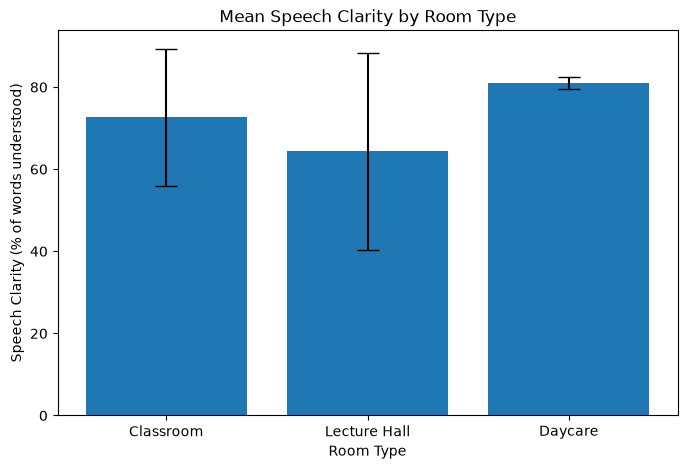

A. What does the height of each bar (the **mean**) tell a designer about that room type? (1 pt) What do the **error bars** (the standard deviation) tell them? (1 pt)

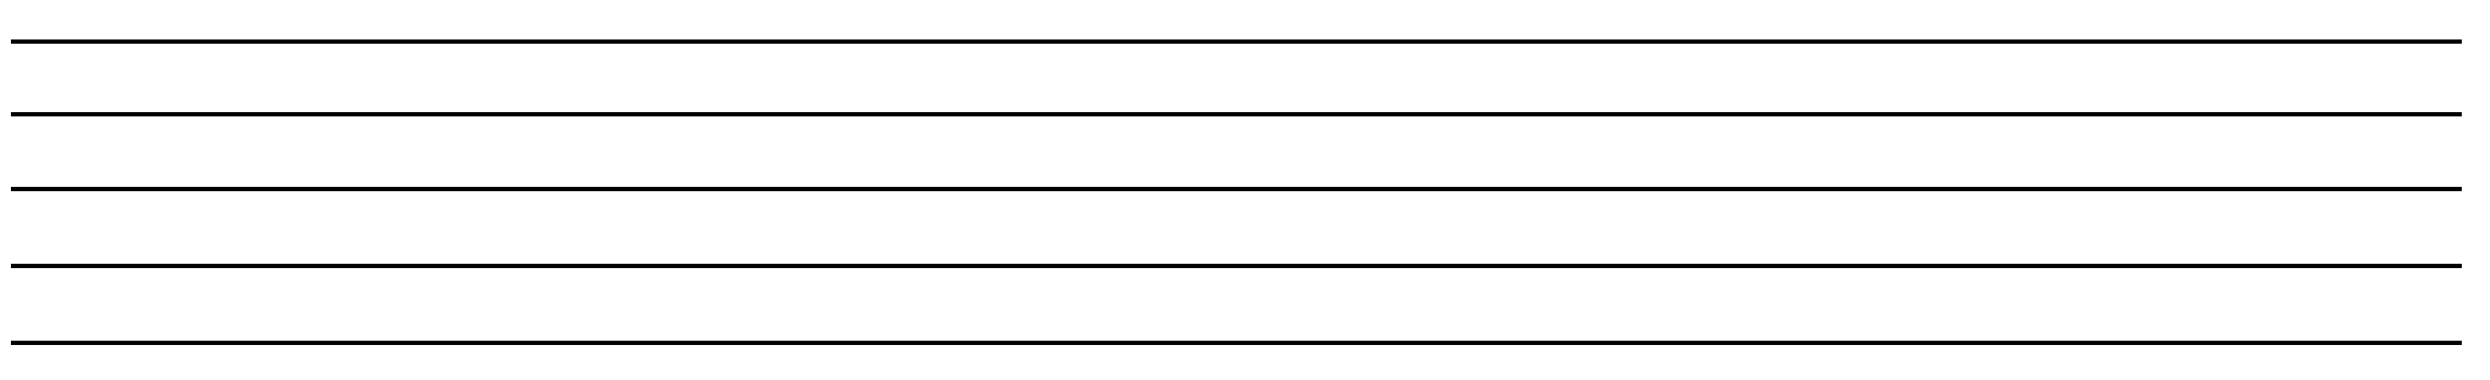

B. Lecture halls have the **lowest** mean and the **longest** error bars, while daycare rooms have the **highest** mean and the shortest error bars. Explain how the error bars help a designer judge **risk**, meaning how predictable a result is (1 pt). If one room type had a slightly higher mean than another but much longer error bars, why might a designer treat it as the riskier choice? (1 pt)

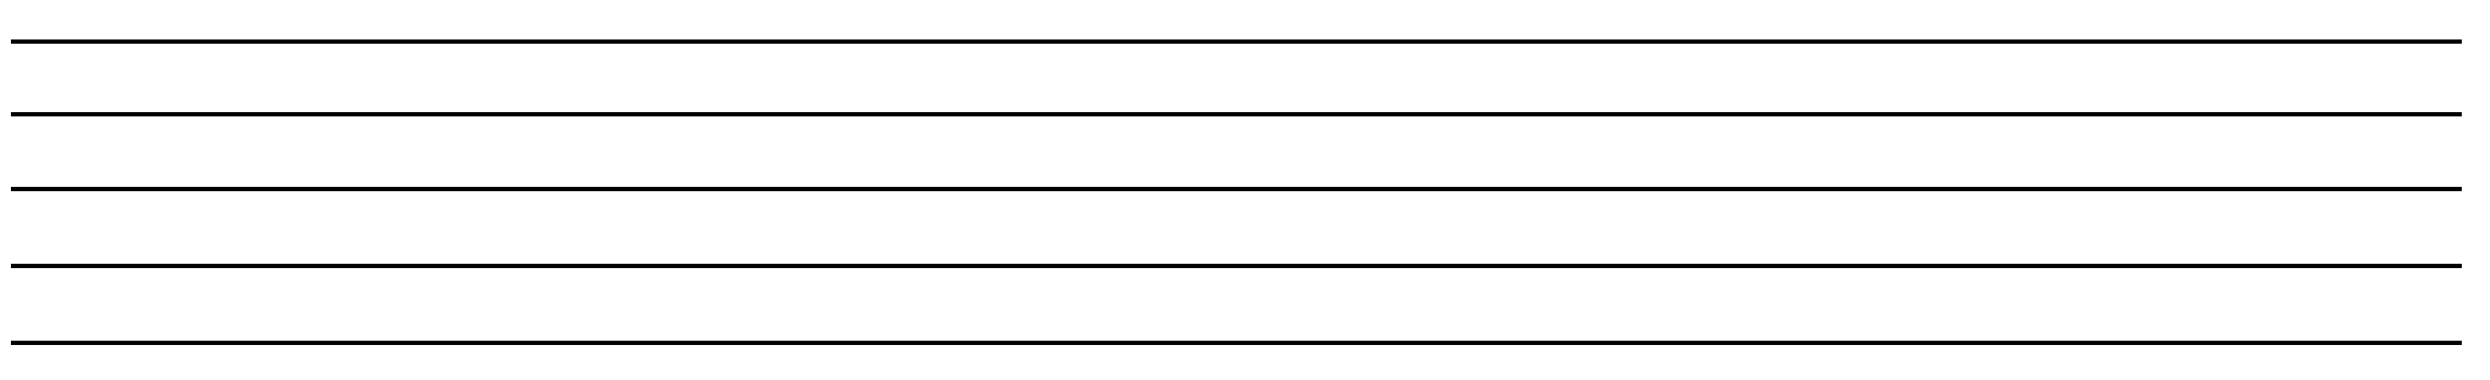

## 2. Optimization Method Comparison (3 points)

In Part 1, Task 3, you used `scipy.optimize.minimize()` to find the best panel coverage, and a coarse grid search to pick its starting guess.

A. Name one **limitation** of using a very fine grid search to find an optimum (like the million-point insulation search from class) (1 pt).

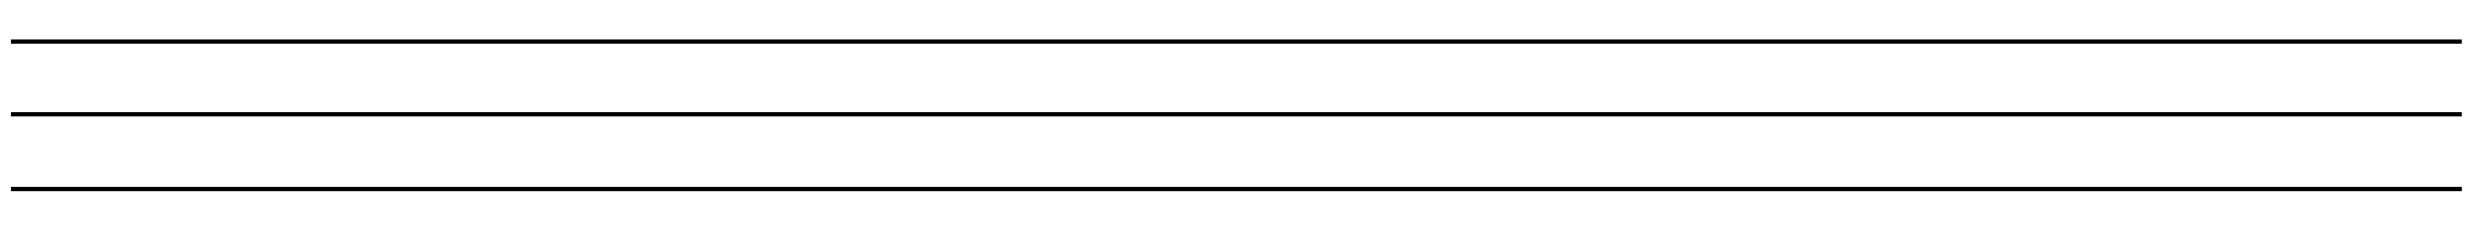

B. A real room design has many acoustic design variables (panel coverage on the ceiling, panels on each of the four walls, panel thickness, carpet or hard floor, ceiling height, and more). Explain the **curse of dimensionality** and why it makes grid search impractical for problems like this (2 pts).

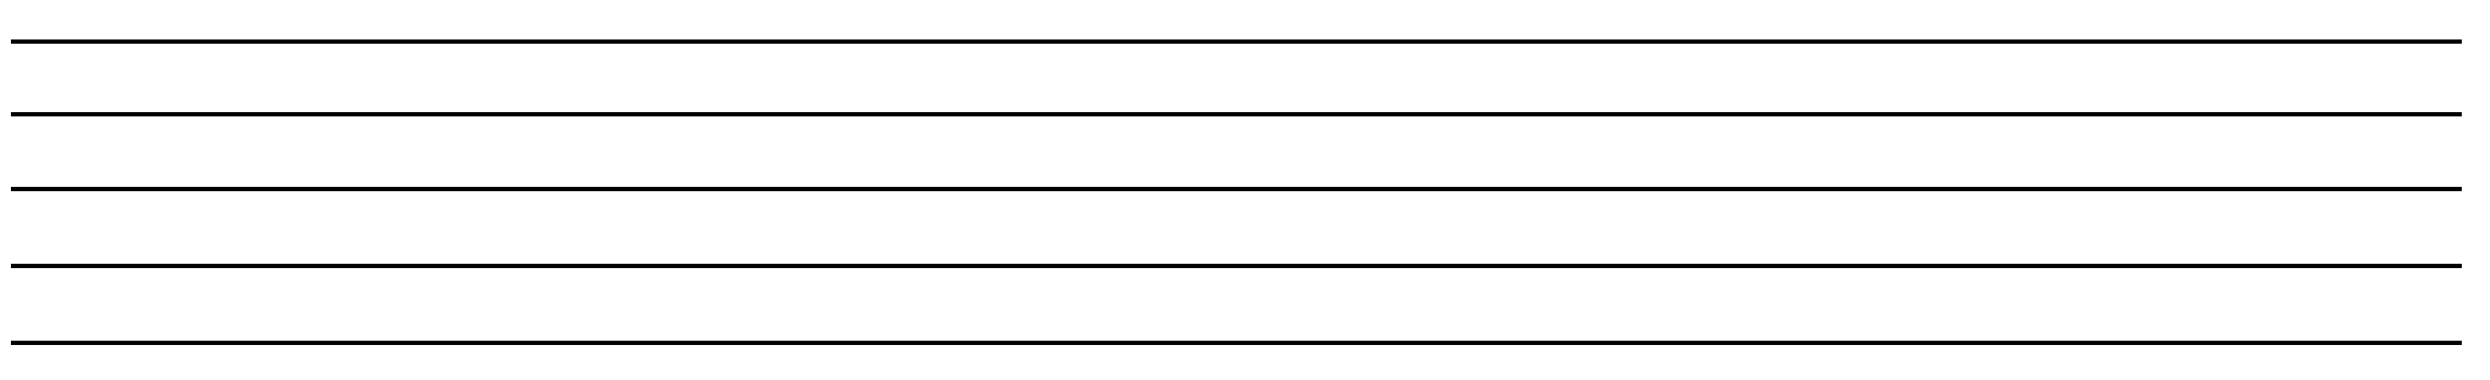

## 3. Interpreting the Cubic Model (4 points)

Here are the fitted models from Part 1, Task 2.

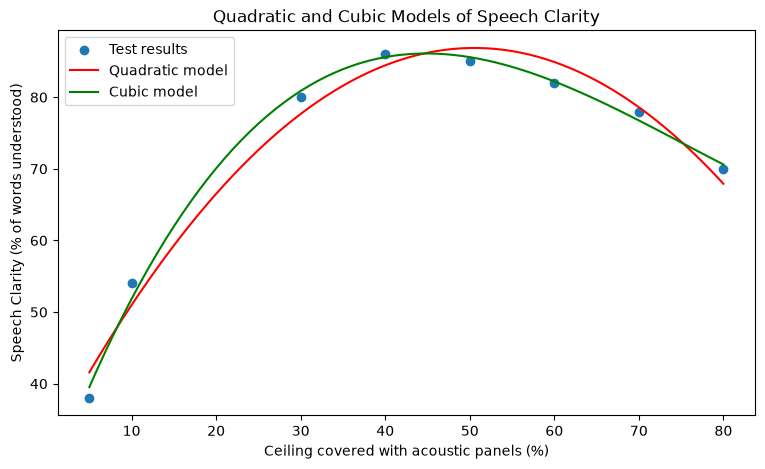

A. Task 3 found that the best panel coverage is about **44.8%** of the ceiling, with a predicted speech clarity of about **86.1%**. Why does minimizing the **negative** of the model find the **maximum**? (1 pt) What does this result mean for a designer choosing how many panels to install? (1 pt)

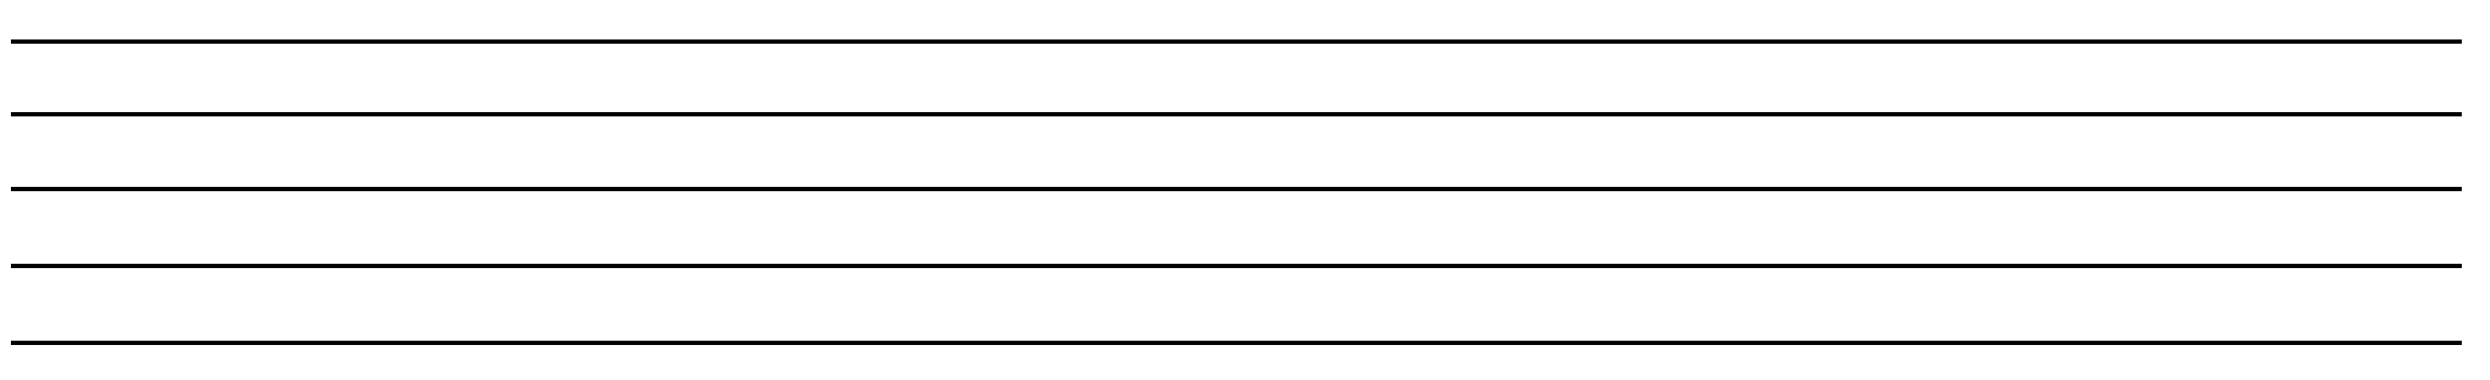

B. Look at the cubic curve between 10% and 44.8% coverage. Going from 10% to 20% coverage raises the predicted clarity by about 18.2 points, but going from 30% to 40% raises it by only about 4.7. What is happening to the **slope** of the curve as the coverage increases toward the peak? (1 pt) Why might a designer choose a coverage somewhat **below** 44.8% even though that is where clarity is highest? (1 pt)

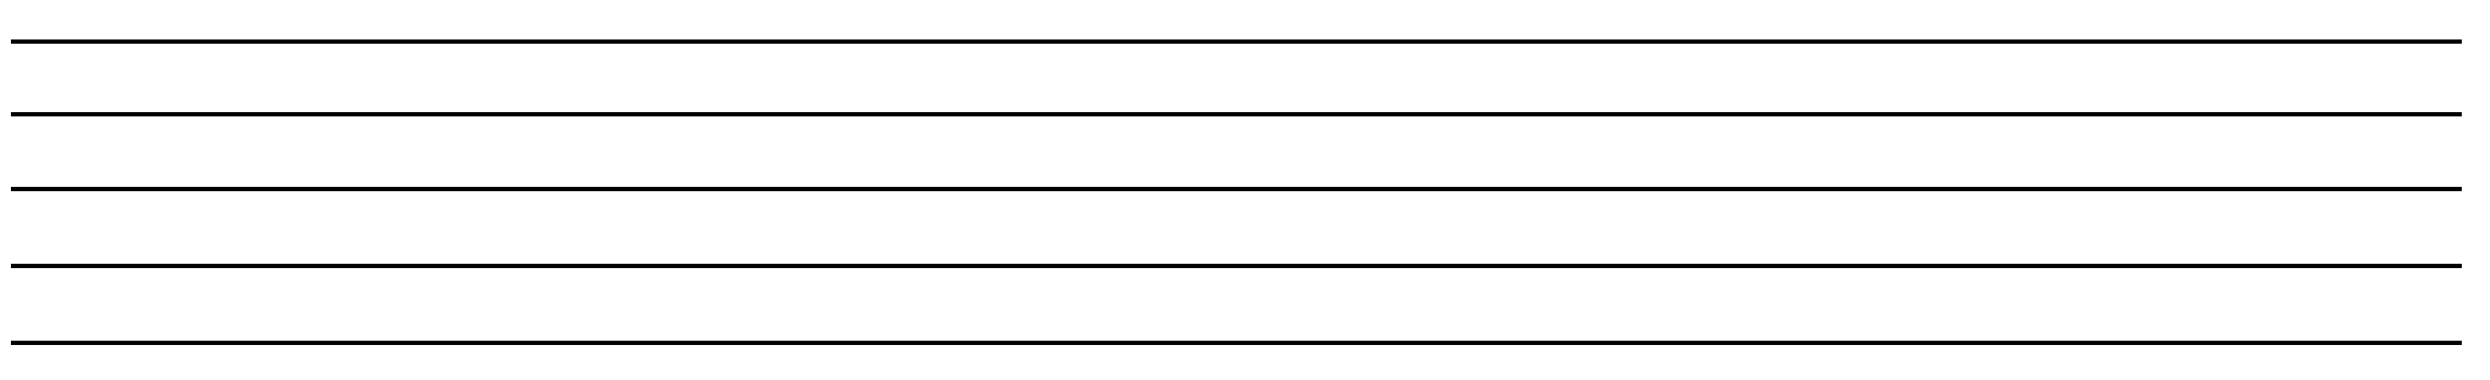

**Submission:** Please submit 1) the link (make sure that your sharing access is on) and 2) the static .ipynb as a file upload. You will not get any credit if one of those is missing.

To download the static .ipynb file go to file, download, .ipynb